# UDepth — FLSea, avaliador atualizado com rescaled

Inferência do UDepth-RMI pré-treinado, sem treinamento. Usa diretamente `scripts/evaluate_flsea.py` do repositório do grupo, no commit fixado `fa5f0c8badef0a22574802cad148d364c0da23f5`, da PR #2 de correção. Não depende de a PR já ter sido incorporada à main.

A avaliação usa os mesmos 120 pares de seis sequências do FLSea-VI v5. O esperado é 119 frames válidos e 595 linhas: `ssi`, `median`, `constant`, `rescaled` e `global-ssi`.

**A nova execução só é considerada tecnicamente concluída quando a seção 3 imprime `VALIDACAO_TECNICA_CONCLUIDA`.** As verificações incluem IDs, referências, controle constante, checkpoint e 119 NPYs com hashes válidos. Os resultados anteriores ficam preservados no histórico, sem serem apresentados como resultados rescaled.

Execute as seções 1 a 5. A seção 3 prepara os arquivos faltantes e executa a avaliação; o cache é persistido no Drive para retomada. A conclusão final mostra exclusivamente os números da execução atual.

## 1. Configuração

CPU é suficiente e GPU é opcional. A autorização do Drive deve usar a conta vma3@cin.ufpe.br. A execução é gravada em uma pasta nova; os resultados e mapas anteriores permanecem preservados.

In [2]:
from pathlib import Path
import importlib.util, json, os, sys, subprocess
MONTAR_DRIVE = True
DISPOSITIVO = 'auto'
PASTA_FLSEA_LOCAL = ''
EXIBIR_FIGURAS = True
try:
    EM_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    EM_COLAB = False
if EM_COLAB and MONTAR_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/projeto_profundidade')
else:
    BASE = Path.cwd()/'resultados'
ROOT = BASE/'UDepth_FLSea_fa5f0c8b_rescaled_120'
ROOT.mkdir(parents=True,exist_ok=True)
REPO_DIR = (Path('/content') if EM_COLAB else Path.cwd())/'Yolo_Depth_udepth_fa5f0c8b'
ASSETS = BASE/'udepth_assets'
os.environ['KAGGLEHUB_CACHE'] = str(BASE/'cache_flsea_grupo')
print('Destino da nova avaliação:',ROOT,flush=True)


Mounted at /content/drive
Destino da nova avaliação: /content/drive/MyDrive/projeto_profundidade/UDepth_FLSea_fa5f0c8b_rescaled_120


## 2. Ambiente e avaliador fixado

Mantém PyTorch e torchvision do ambiente. Baixa o checkout exato da PR de correção, verifica a integridade dos arquivos versionados e executa os sete testes do UDepth antes da avaliação. Nenhuma fórmula de avaliação é substituída no notebook.

In [3]:
for modulo in ['torch','torchvision']:
    if importlib.util.find_spec(modulo) is None:
        raise RuntimeError('O ambiente precisa de PyTorch e torchvision.')
required={'numpy':'numpy','pandas':'pandas','PIL':'pillow','matplotlib':'matplotlib',
          'tqdm':'tqdm','tifffile':'tifffile','imagecodecs':'imagecodecs',
          'cv2':'opencv-python-headless','kagglehub':'kagglehub==1.0.3','pytest':'pytest'}
missing=[package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable,'-m','pip','install','-q',*missing],check=True)
subprocess.run([sys.executable,'-m','pip','install','-q','--no-deps','ultralytics==8.4.214'],check=True)
import torch
print('Torch:',torch.__version__,'| CUDA:',torch.cuda.is_available())


Torch: 2.14.1+cpu | CUDA: False


In [4]:
import hashlib
import json
import os
import subprocess
import sys
from pathlib import Path
from unittest.mock import patch
import numpy as np

REPO_COMMIT = 'fa5f0c8badef0a22574802cad148d364c0da23f5'
PESOS_SHA256 = 'f97343d3356feca7b8cca1a8951cea38ce1f17eeb3a797a63d98f2bfae764c89'
ALINHAMENTOS = ('ssi', 'median', 'constant', 'rescaled', 'global-ssi')


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8*1024*1024), b''):
            digest.update(block)
    return digest.hexdigest()


def gravar_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix+'.partial')
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)


def preparar_repositorio(repo):
    repo = Path(repo)
    if not repo.exists():
        subprocess.run(['git', 'clone', '--no-checkout', 'https://github.com/AndreFGard/Yolo-Depth-Underwater.git', str(repo)], check=True)
        subprocess.run(['git', '-C', str(repo), 'checkout', '--detach', REPO_COMMIT], check=True)
    actual = subprocess.check_output(['git', '-C', str(repo), 'rev-parse', 'HEAD'], text=True).strip()
    if actual != REPO_COMMIT:
        raise RuntimeError('Checkout diferente do avaliador fixado; use outra pasta para o repositório.')
    subprocess.run(['git', '-C', str(repo), 'diff', '--quiet', 'HEAD', '--', 'src', 'scripts', 'configs', 'artifacts'], check=True)
    sys.path.insert(0, str(repo/'src'))
    for name in list(sys.modules):
        if name == 'yolo_depth_underwater' or name.startswith('yolo_depth_underwater.'):
            sys.modules.pop(name, None)
    print('Avaliador atualizado:', actual, flush=True)
    return repo


def preparar_dados(repo, output, local_root=None):
    from yolo_depth_underwater import flsea
    if not Path(flsea.__file__).resolve().is_relative_to((repo/'src').resolve()):
        raise RuntimeError('Outro checkout foi importado nesta sessão.')
    protocolo = json.loads((repo/'artifacts/udepth_flsea_protocol.json').read_text())
    manifesto = repo/'configs/flsea_eval_frames.csv'
    if sha256(manifesto) != protocolo['manifest_sha256']:
        raise RuntimeError('O manifesto difere do experimento original.')
    frames = flsea.read_manifest(manifesto, flsea.SUBSETS[flsea.Subset.CAI_METZLER])
    keys = [(f.sequence, f.frame_id) for f in frames]
    expected = [(r['sequence'], r['frame_id']) for r in protocolo['frames']]
    if len(keys) != 120 or keys != expected:
        raise RuntimeError('Os 120 pares precisam ser exatamente os mesmos do grupo.')
    if local_root:
        root = Path(local_root).resolve()
        frames = flsea.attach_local_root(frames, root)
    else:
        import kagglehub
        original = kagglehub.dataset_download
        def baixar_v5(handle, *args, **kwargs):
            if handle == flsea.HANDLE:
                handle = 'viseaonlab/flsea-vi/versions/5'
            return original(handle, *args, **kwargs)
        print('Preparando somente os 120 pares FLSea-VI v5; o cache existente será consultado.', flush=True)
        with patch.object(kagglehub, 'dataset_download', baixar_v5):
            frames = flsea.download_frames(frames, workers=2)
        if [(f.sequence, f.frame_id) for f in frames] != keys:
            raise RuntimeError('Download incompleto. Reexecute para retomar os faltantes; não avaliar uma amostra menor.')
        root = frames[0].image_path
        for _ in Path(frames[0].image_remote).parts:
            root = root.parent
    for i, (frame, record) in enumerate(zip(frames, protocolo['frames']), 1):
        if sha256(frame.image_path) != record['rgb_sha256'] or sha256(frame.depth_path) != record['gt_sha256']:
            raise RuntimeError('RGB/GT diferente da versão fixada: '+frame.sequence+'/'+frame.frame_id)
        if frame.image_path != root/frame.image_remote or frame.depth_path != root/frame.depth_remote:
            raise RuntimeError('Os arquivos não estão na mesma raiz de dados.')
        if i % 20 == 0:
            print(f'RGB e GT verificados: {i}/120 pares.', flush=True)
    gravar_json(output/'dados_fixados.json', protocolo)
    return frames, root


def validar_resultados(repo, output, frames):
    import pandas as pd
    from yolo_depth_underwater import evaluation, metrics
    csv_path = output/'udepth_evaluation_flsea.csv'
    table = pd.read_csv(csv_path, dtype={'frame_id':str})
    columns = ['sequence', 'frame_id', 'valid_frac', 'alignment', *metrics.METRIC_NAMES]
    if list(table.columns) != columns or len(table) != 595:
        raise RuntimeError('O CSV precisa conter as colunas do grupo e 595 linhas.')
    if set(table.alignment) != set(ALINHAMENTOS) or table.duplicated(['sequence','frame_id','alignment']).any():
        raise RuntimeError('Alinhamentos ausentes ou linhas duplicadas.')
    if not np.isfinite(table[['valid_frac', *metrics.METRIC_NAMES]].to_numpy()).all():
        raise RuntimeError('Métricas inválidas no CSV.')
    previous = pd.read_csv(repo/'artifacts/udepth_evaluation_flsea.csv', dtype={'frame_id':str})
    expected = set(zip(previous.sequence, previous.frame_id))
    for alignment in ALINHAMENTOS:
        part = table[table.alignment == alignment]
        if len(part) != 119 or set(zip(part.sequence, part.frame_id)) != expected:
            raise RuntimeError('Os frames diferem no alinhamento '+alignment)
    controls = table[table.alignment == 'constant'].merge(previous[previous.alignment == 'constant'], on=['sequence','frame_id'], suffixes=('_new','_old'), validate='one_to_one')
    for field in ['valid_frac', *metrics.METRIC_NAMES]:
        np.testing.assert_allclose(controls[field+'_new'], controls[field+'_old'], atol=2e-6, rtol=0)
    all_keys = {(f.sequence, f.frame_id) for f in frames}
    excluded = sorted(all_keys-expected)
    if excluded != [('red_sea/cross_pyramid_loop','16315964096184783')]:
        raise RuntimeError('O frame excluído mudou.')
    predictions = output/'predicoes_udepth'
    index = pd.read_csv(predictions/'indice_relativas.csv', dtype={'frame_id':str})
    if len(index) != 119 or set(zip(index.sequence,index.frame_id)) != expected:
        raise RuntimeError('Índice de mapas relativos incompleto.')
    for row in index.itertuples():
        path = predictions/row.relative_npy
        if sha256(path) != row.sha256:
            raise RuntimeError('Hash do mapa não confere: '+str(path))
        array = np.load(path, allow_pickle=False)
        if array.dtype != np.float32 or array.ndim != 2 or not np.isfinite(array).all() or (array<=0).any():
            raise RuntimeError('Mapa relativo inválido: '+str(path))
    if len(list((predictions/'alinhadas_ssi').glob('*.png'))) != 119:
        raise RuntimeError('Exportação SSI incompleta.')
    model_protocol = json.loads((output/'cache/protocolo_udepth.json').read_text())
    if model_protocol.get('weights_sha256') != PESOS_SHA256 or model_protocol.get('training') is not False:
        raise RuntimeError('Checkpoint ou protocolo do modelo diferente do esperado.')
    summary = evaluation.summarize(table.to_dict(orient='records'))
    report = {'status':'validacao_tecnica_concluida','evaluator_commit':REPO_COMMIT,
              'dataset_version':5,'n_requested':120,'n_scored':119,'n_csv_rows':len(table),
              'alignments':list(ALINHAMENTOS),'excluded':excluded,'same_frames':True,
              'same_valid_fraction_and_constant':True,'n_relative_maps':len(index),
              'relative_maps_sha256_checked':True,'csv_sha256':sha256(csv_path),
              'model_protocol':model_protocol,'summary':summary,
              'source_sha256':{name:sha256(repo/name) for name in ['scripts/evaluate_flsea.py','src/yolo_depth_underwater/evaluation.py','src/yolo_depth_underwater/metrics.py','src/yolo_depth_underwater/udepth_model.py']}}
    gravar_json(output/'validacao_execucao.json',report)
    table.groupby(['sequence','alignment'],sort=False)[list(metrics.METRIC_NAMES)].mean().reset_index().to_csv(output/'udepth_por_sequencia.csv',index=False)
    print('VALIDACAO_TECNICA_CONCLUIDA: 595 linhas, 119 frames e 119 mapas relativos verificados.',flush=True)
    return table, report


def executar_avaliacao(repo, assets, output, local_root=None, device='auto'):
    repo = preparar_repositorio(repo)
    output = Path(output)
    output.mkdir(parents=True,exist_ok=True)
    frames, root = preparar_dados(repo,output,local_root)
    env = dict(os.environ)
    env['PYTHONPATH'] = str(repo/'src')+os.pathsep+env.get('PYTHONPATH','')
    env['UDEPTH_ASSETS'] = str(assets)
    env['UDEPTH_CACHE'] = str(output/'cache')
    command = [sys.executable,'-u',str(repo/'scripts/evaluate_flsea.py'),
               '--model','udepth','--manifest',str(repo/'configs/flsea_eval_frames.csv'),
               '--subset','arxiv-2507.02148','--local-root',str(root),
               '--rescaled','--global-ssi','--no-include-raw',
               '--out',str(output/'udepth_evaluation_flsea.csv'),
               '--save-predictions',str(output/'predicoes_udepth')]
    if device != 'auto':
        command += ['--device',device]
    gravar_json(output/'execucao.json',{'command':command,'evaluator_commit':REPO_COMMIT,'dataset_version':5,'training':False})
    print('Iniciando inferência/avaliação UDepth, sem treinamento.',flush=True)
    subprocess.run(command,env=env,check=True)
    table, report = validar_resultados(repo,output,frames)
    return table, report, frames

REPO_DIR = preparar_repositorio(REPO_DIR)
ambiente_testes = dict(os.environ)
ambiente_testes['PYTHONPATH'] = str(REPO_DIR/'src')
ambiente_testes['PYTEST_DISABLE_PLUGIN_AUTOLOAD'] = '1'
subprocess.run([sys.executable,'-m','pytest',str(REPO_DIR/'tests/test_udepth.py'),'-q'],
               cwd=REPO_DIR,env=ambiente_testes,check=True)


Avaliador atualizado: fa5f0c8badef0a22574802cad148d364c0da23f5


CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', '/content/Yolo_Depth_udepth_fa5f0c8b/tests/test_udepth.py', '-q'], returncode=0)

## 3. Preparar os mesmos pares e avaliar

Obtém somente os arquivos faltantes do manifesto, na versão 5 do FLSea, e confere os hashes dos 120 pares com o experimento original. Downloads incompletos interrompem a avaliação, para permitir retomada sem reduzir a amostra.

A entrada BGR é convertida para RGB e depois RMI. O avaliador recebe a inversa relativa do UDepth; os NPYs exportados contêm `1/max(inversa,1e-6)`, maior para mais longe, sem GT ou normalização min–max. O nome `disparity` da interface não implica disparidade estéreo calibrada.

`ssi` e `median` usam GT da própria imagem; `rescaled` ajusta somente escala em calibração cruzada; `global-ssi` ajusta escala e deslocamento com a outra metade dos índices originais. A avaliação usa profundidade inversa para os ajustes, máscara de GT finito/positivo, cobertura mínima de 2%, teto de 20 m nas previsões alinhadas e SILog com λ=0,85.

A exportação salva NPYs float32 em `predicoes_udepth/relativas` e PNGs SSI auxiliares em `predicoes_udepth/alinhadas_ssi`. A validação só conclui com 595 linhas, os mesmos 119 IDs, a exclusão esperada e 119 mapas íntegros. A linha `raw` não é usada como profundidade métrica do UDepth.

In [5]:
TABELA_ATUAL, RESULTADO_ATUAL, FRAMES_ATUAIS = executar_avaliacao(
    REPO_DIR,ASSETS,ROOT,local_root=PASTA_FLSEA_LOCAL or None,device=DISPOSITIVO)
print('Validação:',ROOT/'validacao_execucao.json',flush=True)


Avaliador atualizado: fa5f0c8badef0a22574802cad148d364c0da23f5
Preparando somente os 120 pares FLSea-VI v5; o cache existente será consultado.


100%|██████████| 1.02M/1.02M [00:00<00:00, 9.18MB/s]


100%|██████████| 928k/928k [00:00<00:00, 6.11MB/s]


100%|██████████| 2.30M/2.30M [00:00<00:00, 13.4MB/s]


100%|██████████| 1.80M/1.80M [00:00<00:00, 7.90MB/s]


100%|██████████| 0.98M/0.98M [00:00<00:00, 4.94MB/s]

... (232 outputs left out)

100%|██████████| 851k/851k [00:00<00:00, 4.36MB/s]


100%|██████████| 1.63M/1.63M [00:00<00:00, 9.17MB/s]


100%|██████████| 930k/930k [00:00<00:00, 12.2MB/s]


RGB e GT verificados: 20/120 pares.
RGB e GT verificados: 40/120 pares.
RGB e GT verificados: 60/120 pares.
RGB e GT verificados: 80/120 pares.
RGB e GT verificados: 100/120 pares.
RGB e GT verificados: 120/120 pares.
Iniciando inferência/avaliação UDepth, sem treinamento.
VALIDACAO_TECNICA_CONCLUIDA: 595 linhas, 119 frames e 119 mapas relativos verificados.
Validação: /content/drive/MyDrive/projeto_profundidade/UDepth_FLSea_fa5f0c8b_rescaled_120/validacao_execucao.json


## 4. Resultados da execução atual

Médias por imagem, com protocolos identificados. A comparação com os resultados anteriores usa os mesmos frames; os modelos dos colegas não são reexecutados aqui. O CSV atual e o registro de validação devem acompanhar uma futura contribuição ao Git.

In [6]:
from IPython.display import display
import pandas as pd
RESUMO_ATUAL = TABELA_ATUAL.groupby('alignment',sort=False)[['AbsRel','RMSE','d1','d2','d3','SILog']].mean()
display(RESUMO_ATUAL)
display(TABELA_ATUAL.groupby(['sequence','alignment'],sort=False).size().rename('N').unstack())
print('CSV:',ROOT/'udepth_evaluation_flsea.csv')
print('Mapas relativos:',ROOT/'predicoes_udepth/relativas')
print('Índice e hashes:',ROOT/'predicoes_udepth/indice_relativas.csv')
print('Proveniência e validação:',ROOT/'validacao_execucao.json')


,AbsRel,RMSE,d1,d2,d3,SILog
alignment,,,,,,
ssi,0.129105,0.927781,0.846621,0.961678,0.987001,17.540645
median,0.229504,1.620826,0.724297,0.897238,0.954298,25.580715
constant,0.323030,1.634633,0.399664,0.713621,0.877019,44.479728
rescaled,0.484915,2.157244,0.320547,0.625806,0.822283,30.291517
global-ssi,0.349646,1.475543,0.338861,0.644677,0.857507,26.865299


alignment,ssi,median,constant,rescaled,global-ssi
sequence,,,,,
canyons/flatiron,20,20,20,20,20
canyons/u_canyon,20,20,20,20,20
red_sea/big_dice_loop,20,20,20,20,20
red_sea/coral_table_loop,20,20,20,20,20
red_sea/cross_pyramid_loop,19,19,19,19,19
red_sea/sub_pier,20,20,20,20,20


CSV: /content/drive/MyDrive/projeto_profundidade/UDepth_FLSea_fa5f0c8b_rescaled_120/udepth_evaluation_flsea.csv
Mapas relativos: /content/drive/MyDrive/projeto_profundidade/UDepth_FLSea_fa5f0c8b_rescaled_120/predicoes_udepth/relativas
Índice e hashes: /content/drive/MyDrive/projeto_profundidade/UDepth_FLSea_fa5f0c8b_rescaled_120/predicoes_udepth/indice_relativas.csv
Proveniência e validação: /content/drive/MyDrive/projeto_profundidade/UDepth_FLSea_fa5f0c8b_rescaled_120/validacao_execucao.json


## 5. Exemplos da execução atual

Um frame por sequência: RGB, profundidade relativa sem GT, referência e PNG SSI alinhado. As cores relativas são ajustadas apenas na figura. Referência e SSI compartilham a escala por linha. Regiões sem GT são mascaradas nessas duas colunas.

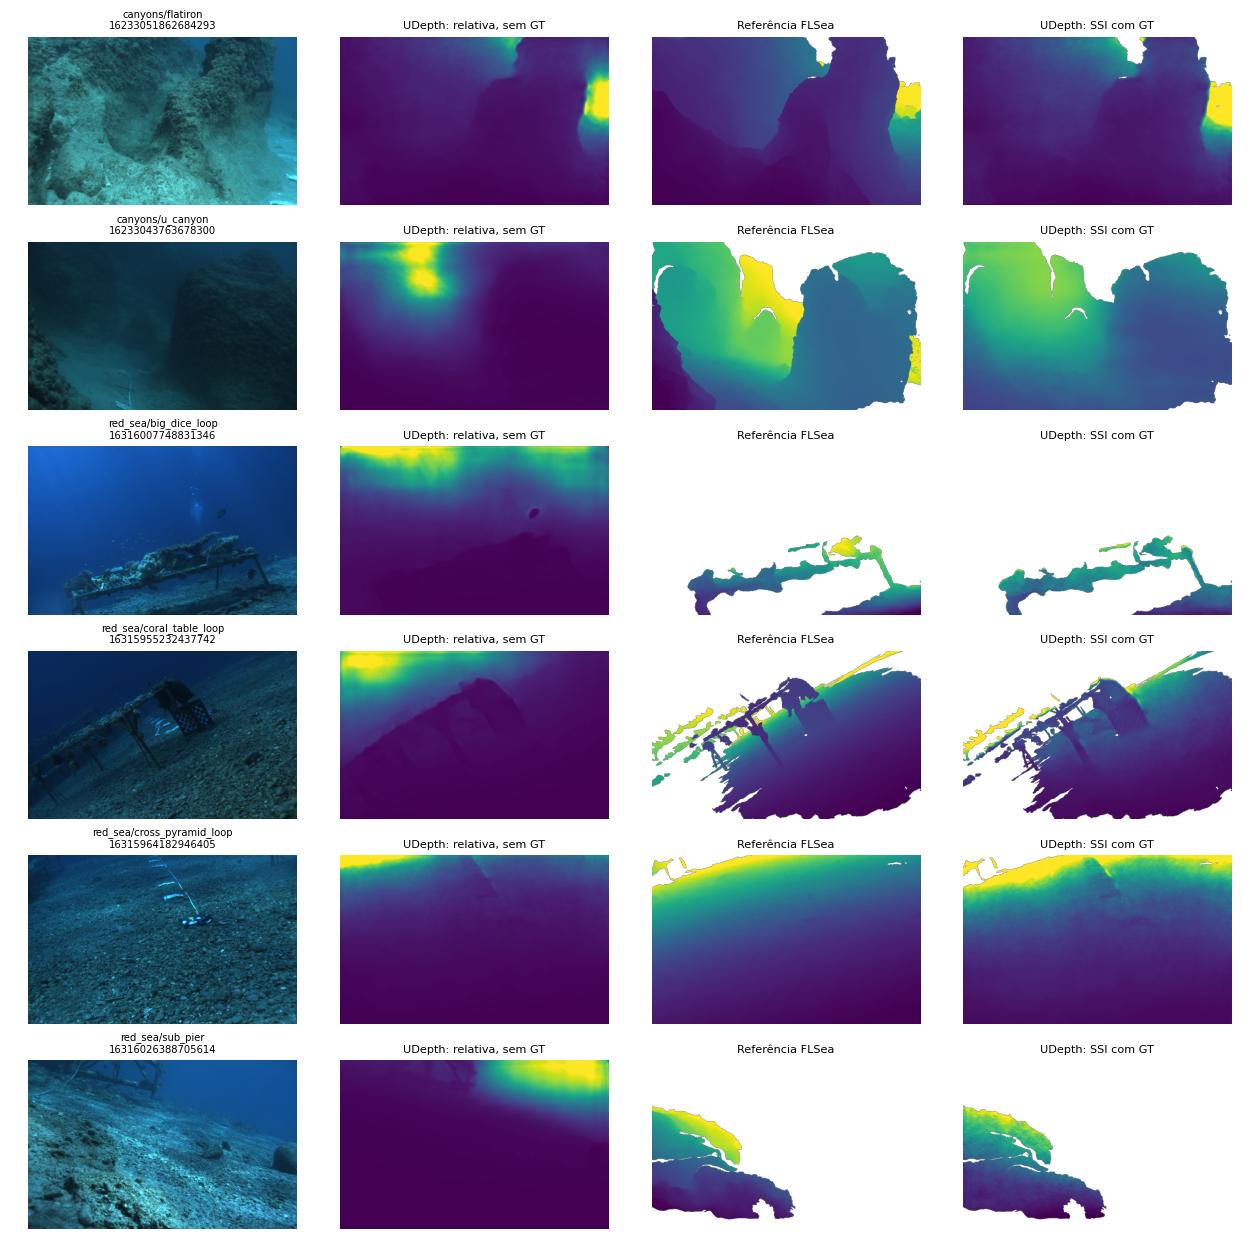

In [7]:
if EXIBIR_FIGURAS:
    import matplotlib.pyplot as plt
    from PIL import Image
    from yolo_depth_underwater import flsea, metrics
    from IPython.display import Image as DisplayImage
    indice = pd.read_csv(ROOT/'predicoes_udepth/indice_relativas.csv',dtype={'frame_id':str})
    exemplos = indice.groupby('sequence',sort=False).first().reset_index()
    lookup = {(f.sequence,f.frame_id):f for f in FRAMES_ATUAIS}
    fig,axes = plt.subplots(len(exemplos),4,figsize=(14,2.3*len(exemplos)),squeeze=False)
    for i,row in enumerate(exemplos.itertuples()):
        bgr,gt = flsea.load_frame(lookup[(row.sequence,row.frame_id)])
        valid = metrics.valid_mask(gt)
        relative = np.load(ROOT/'predicoes_udepth'/row.relative_npy,allow_pickle=False)
        aligned = np.asarray(Image.open(ROOT/'predicoes_udepth/alinhadas_ssi'/(row.frame_id+'.png')),dtype=float)/1000
        lo,hi = np.percentile(gt[valid],[1,99])
        rlo,rhi = np.percentile(relative,[1,99])
        axes[i,0].imshow(bgr[...,::-1]);axes[i,0].set_title(row.sequence+'\n'+row.frame_id,fontsize=8)
        axes[i,1].imshow(relative,cmap='viridis',vmin=rlo,vmax=rhi);axes[i,1].set_title('UDepth: relativa, sem GT',fontsize=9)
        axes[i,2].imshow(np.ma.masked_where(~valid,gt),cmap='viridis',vmin=lo,vmax=hi);axes[i,2].set_title('Referência FLSea',fontsize=9)
        axes[i,3].imshow(np.ma.masked_where(~valid,aligned),cmap='viridis',vmin=lo,vmax=hi);axes[i,3].set_title('UDepth: SSI com GT',fontsize=9)
        for ax in axes[i]:ax.axis('off')
    fig.tight_layout()
    FIGURA_ATUAL = ROOT/'exemplos_atual.jpg'
    fig.savefig(FIGURA_ATUAL,dpi=90,pil_kwargs={'quality':75,'optimize':True})
    plt.close(fig)
    display(DisplayImage(filename=str(FIGURA_ATUAL)))


## Histórico — execução anterior, sem rescaled

### Avaliador anterior, commit da0166ce

UDepth-RMI pré-treinado, sem treinamento adicional. Avaliação com o repositório [Yolo-Depth-Underwater](https://github.com/AndreFGard/Yolo-Depth-Underwater), commit `da0166ce07c2ac05a813ad122010d505d236acf4`.

O conjunto comum é `configs/flsea_eval_frames.csv`, filtrado pelo subconjunto padrão `arxiv-2507.02148`: **120 pares de seis sequências**, com 20 quadros espaçados temporalmente por sequência. O script avaliou **119 imagens**, as mesmas dos três CSVs versionados dos colegas. Uma imagem de Cross Pyramid Loop foi excluída pelo critério original de cobertura mínima de GT. Não houve nova amostragem.

**Resultados executados e verificados localmente em CPU.** A extensão do script registra o UDepth e exporta seus mapas relativos em NPY float32, além dos PNGs SSI auxiliares. O avaliador, as fórmulas de métricas, máscaras e alinhamentos são os do repositório, sem substituições. Os demais modelos da tabela usam resultados já versionados pelos colegas; não foram reexecutados nesta etapa.

| Alinhamento do repositório | N | AbsRel ↓ | RMSE alinhado ↓ | δ1 ↑ | δ2 ↑ | δ3 ↑ | SILog ↓ |
|---|---:|---:|---:|---:|---:|---:|---:|
| ssi | 119 | 0,1291 | 0,9278 | 0,8466 | 0,9617 | 0,9870 | 17,5406 |
| median | 119 | 0,2295 | 1,6208 | 0,7243 | 0,8972 | 0,9543 | 25,5807 |
| constant | 119 | 0,3230 | 1,6346 | 0,3997 | 0,7136 | 0,8770 | 44,4797 |
| global-ssi | 119 | 0,3496 | 1,4755 | 0,3389 | 0,6447 | 0,8575 | 26,8653 |

`ssi` é a linha usada no relatório do grupo. `ssi` e `median` usam o GT da própria imagem; `global-ssi` ajusta a escala/deslocamento com outros quadros, em duas metades alternadas. `constant` é o controle sem estrutura da cena. As linhas descrevem protocolos diferentes, não modelos diferentes.

O estudo anterior de 150 imagens foi preservado como piloto no apêndice, com execução desativada. Seus números, incluindo δ1 de 64,1%, não pertencem à tabela comum acima.

## Apêndice — estudo piloto anterior, 150 imagens

As figuras e os resultados abaixo pertencem ao estudo anterior de Flatiron, U Canyon e Northeast Path, com 50 imagens por sequência. A amostra e o espaço de alinhamento são diferentes do protocolo comum do grupo. As células de código deste apêndice estão desativadas e não participam da nova avaliação. Nenhum resultado do piloto é misturado à tabela principal.

### Piloto anterior — profundidade relativa

**Victor Mendonça Aguiar.** Inferência do UDepth-RMI pré-treinado, mapas numéricos de profundidade relativa e avaliação em imagens subaquáticas, com pesos congelados.

As saídas do FLSea abaixo incluem execução anterior no Colab para Flatiron e verificação local em CPU para o estudo ampliado de três sequências. Os resultados do USOD10K e a comparação de desempenho no equipamento do grupo permanecem dependentes de suas respectivas execuções.

**Resultados reais já obtidos — alinhamento pela mediana, média por imagem:**

| Sequência | N | AbsRel ↓ | Spearman ↑ |
|---|---:|---:|---:|
| Flatiron | 50 | 0,2862 | 0,9192 |
| U Canyon | 50 | 0,5261 | 0,8824 |
| Northeast Path | 50 | 0,2272 | 0,8947 |
| Total | 150 | 0,3465 | 0,8987 |

Total: δ1=0,6410; δ2=0,8591; δ3=0,9274; SILog(λ=0,85)=33,5134; RMSE após alinhamento=3,6685 na unidade do GT. **Não é profundidade métrica calibrada.** O conjunto é uma seleção do projeto, não um split oficial nem todo o FLSea. Os resultados não demonstram comparação com os modelos dos colegas.



### 1. Configuração

FLSea-VI v5: seleção de 50 pares por sequência, semente 42. O conjunto ampliado contém Flatiron, U Canyon e Northeast Path.


In [8]:
if False:
    from pathlib import Path
    import sys, os, json, importlib.util

    MONTAR_DRIVE = True
    PASTA_RESULTADOS = 'UDepth_FLSea_Flatiron_50_v2'
    DISPOSITIVO = 'auto'
    BAIXAR_FLSEA = True
    CAMINHO_IMAGEM = ''
    CSV_FLSEA = ''
    PASTA_RGB_FLSEA = ''
    PASTA_GT_FLSEA = ''
    PASTA_MASCARAS_FLSEA = ''
    CENA_FLSEA = 'flatiron'
    DIVISOR_ARMAZENAMENTO_GT = 1.0
    UNIDADE_GT = 'm'
    GEOMETRIA_GT = 'axis_depth'
    CENAS_TESTE = ''
    IMAGENS_POR_CENA = 50
    SEMENTE = 42
    INPUT_HW = (480, 640)
    GERAR_ZIP = False

    try:
        EM_COLAB = importlib.util.find_spec('google.colab') is not None
    except ModuleNotFoundError:
        EM_COLAB = False
    if MONTAR_DRIVE and EM_COLAB:
        from google.colab import drive
        drive.mount('/content/drive')
        BASE_RESULTADOS = Path('/content/drive/MyDrive/projeto_profundidade')
    else:
        BASE_RESULTADOS = Path.cwd() / 'resultados'
    ROOT = BASE_RESULTADOS / PASTA_RESULTADOS
    ROOT.mkdir(parents=True, exist_ok=True)
    ASSETS = (Path('/content') if EM_COLAB else Path.cwd()) / 'udepth_assets'
    print('Fluxo: UDepth pré-treinado, sem treinamento')
    print('Resultados:', ROOT)

    DADOS_FLSEA = BASE_RESULTADOS / 'FLSea_parcial'
    print('FLSea: Flatiron,', IMAGENS_POR_CENA, 'pares individuais; sem ZIP completo.')

    EXIBIR_FIGURAS = True
    CSV_TESTE_USOD10K = ""
    CONFIRMAR_TESTE_COMUM = False
    EXECUTAR_BENCHMARK = False


### 2. Ambiente e código

Preserva PyTorch/torchvision do Colab. Instala somente dependências auxiliares ausentes e a
versão testada do cliente Kaggle. `imagecodecs` permite ler os TIFFs de profundidade FLSea com LZW.
O código e checkpoint RMI do UDepth são verificados por hash. Não baixa USOD10K nem inicia treino.


In [9]:
if False:
    import subprocess, importlib.util
    for name in ('torch', 'torchvision'):
        if importlib.util.find_spec(name) is None:
            raise RuntimeError('Use um ambiente padrão do Colab com PyTorch e torchvision instalados.')
    required = {'numpy':'numpy', 'pandas':'pandas', 'scipy':'scipy', 'PIL':'pillow',
                'matplotlib':'matplotlib', 'pytest':'pytest', 'tifffile':'tifffile', 'imagecodecs':'imagecodecs', 'kagglehub':'kagglehub==1.0.3'}
    missing = [pkg for mod,pkg in required.items() if importlib.util.find_spec(mod) is None]
    from importlib.metadata import version
    if importlib.util.find_spec('kagglehub') is not None and version('kagglehub') != '1.0.3':
        missing.append('kagglehub==1.0.3')
    if missing:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)
    import torch
    print('Torch:', torch.__version__, '| CUDA disponível:', torch.cuda.is_available())
    print('CPU também é suportada para esta inferência; não há treino neste notebook.')


In [10]:
if False:
    import base64, gzip, json
    FONTES_FLSEA = json.loads(gzip.decompress(base64.b64decode('...')).decode("utf-8"))
    CODIGO_DIR = ROOT / 'codigo'
    CODIGO_DIR.mkdir(exist_ok=True)
    for nome, conteudo in FONTES_FLSEA.items():
        (CODIGO_DIR / nome).write_text(conteudo, encoding='utf-8')
    if str(CODIGO_DIR) not in sys.path:
        sys.path.insert(0, str(CODIGO_DIR))
    for nome in ['udepth_flsea_workflow', 'flsea_subset']:
        sys.modules.pop(nome, None)
    from udepth_flsea_workflow import (prepare_assets, UDepthRelative, save_demo, create_manifest,
                                      freeze_test_set, evaluate_flsea, write_json, sha256_file)
    from flsea_subset import prepare_flsea_subset
    CATALOGO_FLSEA = json.loads((CODIGO_DIR / 'catalogo_flatiron_v5.json').read_text())
    subprocess.run([sys.executable, '-m', 'pytest', '-q', str(CODIGO_DIR / 'test_udepth_flsea.py')],
                   cwd=str(CODIGO_DIR), check=True)
    print('Código verificado. Catálogo Flatiron v5:', len(CATALOGO_FLSEA), 'pares por ID.')


### 3. Obter o subconjunto FLSea e carregar o UDepth

Carrega `model_RMI.pth`, com todos os parâmetros congelados e `eval()`/`inference_mode()`.
A entrada segue o RMI oficial: **R, máximo entre G/B, intensidade**, antes do resize para 480×640.

**Representação adotada antes do teste:** a saída bruta do checkpoint é tratada como
profundidade inversa relativa, conforme a convenção já usada neste projeto.
O repositório chama essa saída de `depth`; ela não é uma disparidade estéreo calibrada em pixels.
A conversão numérica neste fluxo é

\[
z_{rel}=\frac{1}{\max(d_{bruto},10^{-6})}.
\]

Assim, valores maiores no mapa final significam maior profundidade. Trocar a paleta de cores
não faria essa conversão. Não se aplica um valor arbitrário de distância focal × baseline
para alegar metros. Nenhum GT do FLSea participa da inferência ou da decisão de inverter.

**Variante avaliada:** UDepth-RMI, saída da rede sem o pós-processamento CPD/guidedfilter
do script de visualização oficial. Essa escolha fica registrada nos resultados.
**Download parcial:** seleção aleatória por ID, com semente fixa, sobre os 2.474 pares da sequência.
O GT termina em `_SeaErra_abs_depth.tif`, enquanto o RGB original usa o mesmo timestamp em `imgs/`.
Esses nomes são pareados explicitamente no catálogo; um mapa sem RGB correspondente não é incluído.
Os TIFFs de referência são escalares float32. Valores finitos e positivos são os pixels válidos.
O GT é usado na sua escala fornecida (metros; divisor 1), sem normalização de cada imagem.

A seleção é salva antes de qualquer inferência. Cada arquivo é verificado por tamanho, leitura e hash.
Não há alternativa automática que baixe o ZIP completo se ocorrer um erro.


In [11]:
if False:
    CSV_FLSEA_AUTO = None
    INFO_DOWNLOAD_FLSEA = None
    if BAIXAR_FLSEA and not CSV_FLSEA and not (PASTA_RGB_FLSEA and PASTA_GT_FLSEA):
        CSV_FLSEA_AUTO, INFO_DOWNLOAD_FLSEA = prepare_flsea_subset(
            DADOS_FLSEA, ROOT / 'catalogo_flsea_auto.csv', CATALOGO_FLSEA,
            n=IMAGENS_POR_CENA, seed=SEMENTE, workers=3)
        write_json(ROOT / 'preparacao_flsea.json', INFO_DOWNLOAD_FLSEA)
        print('Pares prontos:', CSV_FLSEA_AUTO)
        print('Dados persistentes:', DADOS_FLSEA)
    else:
        print('Usando CSV/pastas informados, ou download automático desativado.')


In [12]:
if False:
    ASSETS = prepare_assets(ASSETS)
    MODELO = UDepthRelative(ASSETS, device=DISPOSITIVO, input_hw=INPUT_HW)
    write_json(ROOT / 'protocolo_modelo.json', MODELO.protocol)
    print('Modelo carregado:', MODELO.protocol['model'])
    print('Dispositivo efetivo:', MODELO.device)
    print('Treinamento:', MODELO.protocol['training'])
    print('Conversão:', MODELO.protocol['conversion'])


### 4. Gerar um mapa de profundidade relativa do FLSea

Com a configuração padrão, a imagem de exemplo vem dos 50 pares FLSea selecionados.
A figura compara o RGB com o mapa numérico convertido; a avaliação contra o GT ocorre na seção 6.
`inversa_bruta.npy` preserva a saída original; **`profundidade_relativa.npy`** contém os valores
de profundidade relativa. Valores maiores significam mais longe; não são metros calibrados.
O NPY não recebe normalização min–max. Percentis 1–99 afetam somente as cores da figura.


In [13]:
if False:
    import csv
    from IPython.display import Image as _DisplayImage, display

    def DisplayImage(filename, **kwargs):
        import io
        from PIL import Image as _PILImage
        with _PILImage.open(filename) as original:
            preview = original.convert('RGB')
            preview.thumbnail((1200, 1600), _PILImage.Resampling.LANCZOS)
            buffer = io.BytesIO()
            preview.save(buffer, format='JPEG', quality=75, optimize=True)
        return _DisplayImage(data=buffer.getvalue(), format='jpeg', **kwargs)

    if CAMINHO_IMAGEM:
        IMAGEM_ENTRADA = Path(CAMINHO_IMAGEM)
    elif CSV_FLSEA_AUTO is not None or CSV_FLSEA:
        caminho_csv = Path(CSV_FLSEA or CSV_FLSEA_AUTO)
        with caminho_csv.open(encoding='utf-8-sig', newline='') as stream:
            primeira = next(csv.DictReader(stream))
        IMAGEM_ENTRADA = Path(primeira['rgb'])
        if not IMAGEM_ENTRADA.is_absolute():
            IMAGEM_ENTRADA = caminho_csv.parent / IMAGEM_ENTRADA
    else:
        IMAGEM_ENTRADA = ASSETS / 'data/imgs/00002.png'
    FIGURA_DEMO = save_demo(MODELO, IMAGEM_ENTRADA, ROOT / 'demonstracao')
    if EXIBIR_FIGURAS: display(DisplayImage(filename=str(FIGURA_DEMO)))
    print('Mapa numérico:', ROOT / 'demonstracao/profundidade_relativa.npy')
    print('Origem RGB:', IMAGEM_ENTRADA)
    print('A demonstração individual não substitui a avaliação dos 50 pares na seção 6.')


### 5. Pares RGB e profundidade de referência do FLSea

Teste externo definido neste projeto, sem alegação de divisão oficial dos autores. Os pares usam timestamps correspondentes; mapas sem imagem RGB não entram no catálogo. A seleção é fixada antes da inferência, com hashes dos arquivos.

| Campo | Conteúdo |
|---|---|
| `id`, `scene` | Identificador do quadro e sequência |
| `rgb`, `depth` | RGB e referência numérica correspondentes |
| `depth_scale` | Divisor de armazenamento do GT |
| `unit` | Unidade explícita: `m` ou `relative` |
| `geometry` | Profundidade no eixo óptico (`axis_depth`) ou distância radial (`range`) |
| `mask` | Máscara opcional de pixels válidos |
| `array_key`, `mask_key` | Chaves de matrizes NPZ/MAT, quando aplicáveis |
| `fx`, `fy`, `cx`, `cy` | Intrínsecos para converter distância radial em profundidade no eixo óptico |

A referência é numérica, sem inferir unidade pela aparência da imagem. A lista e os hashes são gravados em `FLSea/teste_fixado.csv` e `teste_fixado.json`.


In [14]:
if False:
    import csv
    TEMPLATE_FLSEA = ROOT / 'modelo_manifesto_flsea.csv'
    if not TEMPLATE_FLSEA.exists():
        with TEMPLATE_FLSEA.open('w', newline='', encoding='utf-8') as f:
            csv.writer(f).writerow(['id','scene','rgb','depth','depth_scale','unit','geometry',
                                   'mask','array_key','mask_key','fx','fy','cx','cy'])
    TESTE_FLSEA = None
    MANIFESTO_FLSEA = None
    if CSV_FLSEA:
        MANIFESTO_FLSEA = Path(CSV_FLSEA)
    elif CSV_FLSEA_AUTO is not None:
        MANIFESTO_FLSEA = CSV_FLSEA_AUTO
    elif PASTA_RGB_FLSEA and PASTA_GT_FLSEA:
        MANIFESTO_FLSEA = create_manifest(PASTA_RGB_FLSEA, PASTA_GT_FLSEA, ROOT / 'catalogo_flsea.csv',
                                         CENA_FLSEA, DIVISOR_ARMAZENAMENTO_GT, UNIDADE_GT, GEOMETRIA_GT,
                                         PASTA_MASCARAS_FLSEA)
    if MANIFESTO_FLSEA is not None:
        TESTE_FLSEA = freeze_test_set(MANIFESTO_FLSEA, ROOT / 'FLSea', MODELO.protocol,
                                      scenes=CENAS_TESTE, n_per_scene=IMAGENS_POR_CENA, seed=SEMENTE)
        print('Teste fixado:', TESTE_FLSEA['n_images'], 'imagens | cenas:', TESTE_FLSEA['scenes'])
        print('Assinatura:', TESTE_FLSEA['signature'])
        print('Lista:', ROOT / 'FLSea/teste_fixado.csv')
    else:
        print('FLSea pendente: informe CSV_FLSEA ou as pastas RGB e GT na seção 1.')
        print('Modelo de CSV:', TEMPLATE_FLSEA)
        write_json(ROOT / 'estado_udepth_flsea.json', {'status':'pendente_dados_flsea',
                   'model_training':False, 'inference_demo_ready':(ROOT/'demonstracao/profundidade_relativa.npy').is_file(),
                   'flsea_evaluated':False})


### 6. Avaliar o UDepth no teste escolhido do FLSea

Compara **profundidade relativa convertida** e GT de profundidade, usando apenas pixels
de GT finito/positivo e a máscara fornecida. A predição é interpolada para a resolução do GT;
o GT não é redimensionado silenciosamente. Proporções incompatíveis exigem revisar o alinhamento dos dados.

O protocolo fixo usa escala positiva por **mediana por imagem** somente na avaliação.
Calcula AbsRel, RMSE, δ1/δ2/δ3, SILog (λ=0,85) e Spearman. O alinhamento utiliza GT
para medir a qualidade relativa; **não calibra o modelo em metros para imagens novas**.
RMSE está na unidade do GT após alinhamento. Spearman mede ordenação, não porcentagem de acurácia.

São salvos os NPYs brutos, relativos e alinhados para avaliação, figuras RGB/GT/predição,
CSV por imagem, CSV por cena e resumo. A média geral dá o mesmo peso para cada imagem.
Spearman indefinido em mapas constantes é registrado, não transformado em acurácia.

**Retomada:** reexecutar com o mesmo teste fixado reutiliza imagens concluídas cujos arquivos
e hashes permanecem válidos. Erros/máscaras sem GT válido são reportados; o notebook não
descarta silenciosamente os casos difíceis para melhorar as métricas.

In [15]:
if False:
    RESUMO_FLSEA = None
    if TESTE_FLSEA is not None:
        RESUMO_FLSEA, METRICAS_FLSEA = evaluate_flsea(MODELO, TESTE_FLSEA, ROOT / 'FLSea')
        display(METRICAS_FLSEA)
        print(json.dumps(RESUMO_FLSEA, ensure_ascii=False, indent=2))
        for arquivo in sorted((ROOT / 'FLSea/frames').glob('*/comparacao.png'))[:3]:
            if EXIBIR_FIGURAS: display(DisplayImage(filename=str(arquivo)))
        write_json(ROOT / 'estado_udepth_flsea.json', {'status':'avaliacao_flsea_concluida',
                   'model_training':False, 'flsea_evaluated':True,
                   'n_images':RESUMO_FLSEA['n_images'], 'test_signature':TESTE_FLSEA['signature']})
    else:
        print('FLSea ainda não avaliado: falta indicar os pares RGB/GT do teste na seção 1 e executar a seção 5.')


### 7. Arquivos e exportação

Os resultados são armazenados em `ROOT`, definido na configuração. O pacote preserva mapas, métricas e protocolo. RGB/GT de origem são identificados no CSV e por seus hashes, sem duplicação no pacote.


In [16]:
if False:
    print('Resultados:', ROOT)
    print('Mapa relativo da demonstração:', ROOT / 'demonstracao/profundidade_relativa.npy')
    print('Avaliação FLSea:', 'concluída' if RESUMO_FLSEA is not None else 'pendente de dados/teste escolhido')
    if GERAR_ZIP:
        import shutil
        from datetime import datetime, timezone
        nome = ROOT.parent / ('UDepth_FLSea_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'))
        ZIP_UDEPTH = shutil.make_archive(str(nome), 'zip', root_dir=ROOT)
        print('ZIP:', ZIP_UDEPTH)


### 8. Cinco melhores e cinco piores casos de Flatiron

Ordenação dos 50 casos por AbsRel após alinhamento, com painéis RGB/GT/previsão. O diagnóstico por faixas de GT usa 0–2, 2–5, 5–10 e >10 m. As faixas não alteram a máscara nem a avaliação principal.

A seleção de U Canyon e Northeast Path é fixada antes das novas previsões. Não há treinamento.


In [17]:
if False:
    import base64, gzip, json
    FONTES_AMPLIACAO = json.loads(gzip.decompress(base64.b64decode('...')).decode("utf-8"))
    CODIGO_DIR = ROOT / 'codigo'
    for nome, conteudo in FONTES_AMPLIACAO.items():
        (CODIGO_DIR / nome).write_text(conteudo, encoding='utf-8')
    if str(CODIGO_DIR) not in sys.path: sys.path.insert(0,str(CODIGO_DIR))
    for nome in ['flsea_subset','flsea_project_analysis','copiar_resultados_vma3']:
        sys.modules.pop(nome,None)
    from flsea_project_analysis import (review_pilot, freeze_study_selection,
                                       evaluate_extra_scene, consolidate_study)
    CATALOGOS_EXTRA = json.loads((CODIGO_DIR / 'catalogos_extra_v5.json').read_text())
    STUDY_ROOT = BASE_RESULTADOS / 'UDepth_FLSea_multicenas_150_v3'
    STUDY_ROOT.mkdir(parents=True,exist_ok=True)
    PLANO_150 = freeze_study_selection(CATALOGOS_EXTRA, ROOT / 'FLSea', STUDY_ROOT)
    subprocess.run([sys.executable,'-m','pytest','-q',str(CODIGO_DIR/'test_udepth_flsea.py'),
                    str(CODIGO_DIR/'test_flsea_multicenas.py')],cwd=str(CODIGO_DIR),check=True)
    REVISAO_FLATIRON, RANKING_FLATIRON, FAIXAS_FLATIRON = review_pilot(ROOT/'FLSea',STUDY_ROOT/'analise_flatiron')
    display(RANKING_FLATIRON[['id','absrel','spearman','rmse']].head(5))
    display(RANKING_FLATIRON[['id','absrel','spearman','rmse']].tail(5).iloc[::-1])
    if EXIBIR_FIGURAS: display(DisplayImage(filename=REVISAO_FLATIRON['panels']['melhores']))
    if EXIBIR_FIGURAS: display(DisplayImage(filename=REVISAO_FLATIRON['panels']['piores']))
    display(FAIXAS_FLATIRON)
    print('Seleção das três sequências fixada antes das novas previsões:',STUDY_ROOT/'selecao_multicenas_previa.json')
    print('Todos os casos do piloto permanecem nas métricas; não há exclusão dos piores.')


### 9. Avaliar U Canyon e Northeast Path — mais 100 imagens

São 50 pares por sequência, semente 42, com o mesmo checkpoint, conversão e protocolo do piloto.
O catálogo é da versão 5 do FLSea-VI: 2.895 pares em U Canyon e 1.759 em Northeast Path.
O pareamento usa timestamps exatos; mapas sem RGB correspondente não entram no catálogo de pares.

Somente os 100 pares novos são baixados: aproximadamente **295 MB**. Os arquivos e casos concluídos
são reaproveitados. CPU funciona e GPU é opcional. O conjunto não é um split oficial dos autores.

In [18]:
if False:
    RESUMOS_ADICIONAIS = {}
    for cena, caminho in [('u_canyon','canyons/u_canyon'),('northeast_path','red_sea/northeast_path')]:
        resumo, frame = evaluate_extra_scene(MODELO,CATALOGOS_EXTRA[cena],caminho,cena,
                                             DADOS_FLSEA,STUDY_ROOT,n=50,seed=42)
        RESUMOS_ADICIONAIS[cena] = resumo
        print(cena,json.dumps(resumo,ensure_ascii=False,indent=2))
    print('Duas sequências adicionais concluídas:',sum(r['n_images'] for r in RESUMOS_ADICIONAIS.values()),'imagens.')


### 10. Consolidar as 150 imagens, figuras e texto para relatório

Produz a tabela por sequência, CSV com todas as 150 imagens, gráfico comparativo, relatório HTML
com os painéis incorporados e texto inicial para relatório/artigo. As médias dão o mesmo peso a cada imagem.
Os modelos e protocolos precisam corresponder e cada sequência precisa ter os 50 casos completos.

O relatório distingue ordenação (Spearman), erros após alinhamento e profundidade métrica absoluta.
Flatiron é identificado como piloto; os resultados das novas sequências permanecem separados.

In [19]:
if False:
    RAIZES_AVALIACAO = {'flatiron':ROOT/'FLSea','u_canyon':STUDY_ROOT/'u_canyon',
                        'northeast_path':STUDY_ROOT/'northeast_path'}
    LOCAL_DA_EXECUCAO = ('Execução no ambiente Colab' if EM_COLAB else 'Validação local') + '; dispositivo ' + str(MODELO.device)
    TABELA_150, RESUMO_150 = consolidate_study(RAIZES_AVALIACAO,STUDY_ROOT,STUDY_ROOT/'analise_flatiron',
        LOCAL_DA_EXECUCAO + '; UDepth pré-treinado, protocolo preservado entre sequências')
    display(TABELA_150)
    if EXIBIR_FIGURAS: display(DisplayImage(filename=str(STUDY_ROOT/'comparacao_sequencias.png')))
    print(json.dumps(RESUMO_150,ensure_ascii=False,indent=2))
    print('Relatório:',STUDY_ROOT/'Relatorio_UDepth_FLSea_150.html')
    print('Métricas por sequência:',STUDY_ROOT/'comparacao_por_sequencia.csv')
    print('Métricas das 150 imagens:',STUDY_ROOT/'metricas_150_imagens.csv')


### 11. Resultados no Drive de vma3

A transferência confere a conta `vma3@cin.ufpe.br`, o proprietário, tamanho e hash dos arquivos. O conjunto de 150 imagens é armazenado em `projeto_profundidade/UDepth_FLSea_multicenas_150_v3`.

O ZIP contém mapas relativos numéricos, comparações RGB/GT/previsão, métricas, listas fixadas e relatório. Os NPYs brutos e alinhados permanecem na origem. A conclusão da transferência é registrada pela própria execução.


In [20]:
if False:
    sys.modules.pop('copiar_resultados_vma3',None)
    from copiar_resultados_vma3 import copy_results_to_vma3
    from IPython.display import Markdown
    ZIP_RESULTADOS_VMA3 = Path('/content/UDepth_FLSea_multicenas_150_resultados.zip')
    TRANSFERENCIA_VMA3 = copy_results_to_vma3(STUDY_ROOT,ZIP_RESULTADOS_VMA3)
    link_vma3 = TRANSFERENCIA_VMA3['folder'].get('webViewLink')
    if link_vma3:display(Markdown(f'**[Abrir o estudo de 150 imagens no Drive de vma3]({link_vma3})**'))


### Fontes e protocolo desta edição

- UDepth-RMI pré-treinado oficial, commit e checkpoint verificados por SHA-256; sem treinamento.
- FLSea-VI **versão 5**, sequência **Flatiron**, RGB original e TIFFs float32 de referência.
- Catálogo obtido pela API oficial do Kaggle em 21/11/2026: 2.474 pares por timestamp.
- Seleção de 50 pares, semente 42, antes de consultar previsões ou métricas; aproximadamente 145 MB.
- A conversão recíproca é fixa antes do teste, conforme a convenção inversa usada no projeto.
- A previsão continua relativa. Alinhamento pela mediana usa GT somente para calcular as métricas.
- O teste piloto de uma sequência não representa desempenho em todo o FLSea.
- Arquivos válidos e avaliações concluídas são reaproveitados após desconexões.

Fontes: [UDepth oficial](https://github.com/uf-robopi/UDepth),
[inferência oficial](https://github.com/uf-robopi/UDepth/blob/master/inference.py),
[FLSea-VI oficial](https://www.kaggle.com/datasets/viseaonlab/flsea-vi),
[FLSea — publicação dos autores](https://onlinelibrary.wiley.com/doi/10.1002/rob.70291),
[download individual pelo cliente Kaggle](https://github.com/Kaggle/kagglehub#download-dataset).


### 12. UDepth no teste comum do USOD10K

Avaliação de todos os pares da lista de teste comum do grupo, sem nova amostragem ou treinamento do UDepth. A avaliação real depende dessa lista e dos arquivos correspondentes.

O CSV contém `id,scene,rgb,depth,depth_scale,unit,geometry,split`, com `split=test` em todas as linhas. Caminhos relativos têm o CSV como base. Referências relativas usam `unit=relative`; `depth_scale` explicita o divisor de armazenamento. A máscara é opcional; distância radial requer intrínsecos.

O teste é fixado com hashes antes das previsões. São salvos mapas relativos, métricas por imagem e resumos dos dois alinhamentos. O GT participa somente da avaliação. Casos com métricas afins indefinidas permanecem registrados, sem média parcial apresentada como avaliação completa.


In [21]:
if False:
    FONTE_ENTREGA = '\nimport csv, json, time, platform\nfrom pathlib import Path\nimport numpy as np\nfrom udepth_flsea_workflow import (read_rgb, read_ground_truth, relative_metrics,\n                                  sha256_file, digest_json, write_json, save_npy)\n\n\ndef aligned_metrics(pred, gt, valid, method):\n    if method == \'median\':\n        return relative_metrics(pred, gt, valid)\n    if method != \'scale_shift\':\n        raise ValueError(method)\n    pred, gt, valid = np.asarray(pred, dtype=float), np.asarray(gt, dtype=float), np.asarray(valid, bool)\n\n    relative_metrics(pred, gt, valid)\n    x, y = pred[valid], gt[valid]\n    xc, yc = x-x.mean(), y-y.mean()\n    denominator = float(xc @ xc)\n    if denominator <= np.finfo(float).eps * max(1., float(x @ x)):\n        return {\'status\':\'undefined\', \'reason\':\'previsão constante; escala não identificável\',\n                \'alignment\':method, \'valid_pixels\':int(valid.sum())}, None\n    scale = float((xc @ yc) / denominator)\n    shift = float(y.mean()-scale*x.mean())\n    aligned = scale*pred+shift\n    if scale <= 0 or not np.isfinite(aligned[valid]).all() or (aligned[valid] <= 0).any():\n        return {\'status\':\'undefined\',\'reason\':\'ajuste afim sem escala positiva ou profundidades positivas; sem clipping e sem excluir pixels\',\n                \'alignment\':method,\'scale\':scale,\'shift\':shift,\'valid_pixels\':int(valid.sum())}, None\n\n    p = aligned[valid]\n    e = np.log(p)-np.log(y)\n    ratio = np.maximum(p/y,y/p)\n    from scipy.stats import spearmanr\n    rho = None if len(x)<2 or np.ptp(x)==0 or np.ptp(y)==0 else float(spearmanr(x,y).statistic)\n    result = {\'absrel\':float(np.mean(np.abs(p-y)/y)), \'rmse\':float(np.sqrt(np.mean((p-y)**2))),\n              \'delta1\':float(np.mean(ratio<1.25)), \'delta2\':float(np.mean(ratio<1.25**2)),\n              \'delta3\':float(np.mean(ratio<1.25**3)),\n              \'silog\':float(100*np.sqrt(max(0.,np.var(e)+.15*np.mean(e)**2))),\n              \'spearman\':rho, \'scale\':scale,\'shift\':shift,\'alignment\':method,\n              \'valid_pixels\':int(valid.sum()),\'status\':\'ok\'}\n    return result, aligned.astype(np.float32)\n\n\ndef freeze_common_test(csv_path, output, protocol, confirmed=False):\n    if not confirmed:\n        raise ValueError(\'Confirme que o CSV corresponde ao teste comum do grupo, sem train/val.\')\n    csv_path, output = Path(csv_path).resolve(), Path(output)\n    with csv_path.open(encoding=\'utf-8-sig\',newline=\'\') as f:\n        reader=csv.DictReader(f)\n        required={\'id\',\'scene\',\'rgb\',\'depth\',\'depth_scale\',\'unit\',\'geometry\',\'split\'}\n        if not required.issubset(reader.fieldnames or []):\n            raise ValueError(\'CSV exige: \'+\', \'.join(sorted(required)))\n        rows=list(reader)\n    if not rows or len({(r[\'scene\'],r[\'id\']) for r in rows}) != len(rows):\n        raise ValueError(\'Lista vazia ou IDs duplicados.\')\n    for r in rows:\n        if r[\'split\'].strip().lower() != \'test\':\n            raise ValueError(\'Somente split=test; não usar treino/validação na tabela final.\')\n        if not r[\'id\'].strip() or not r[\'scene\'].strip():raise ValueError(\'ID/cena vazios.\')\n        if r[\'unit\'] not in {\'m\',\'relative\'} or r[\'geometry\'] not in {\'axis_depth\',\'range\'}:\n            raise ValueError(\'Unidade/geometria explícitas obrigatórias.\')\n        if not np.isfinite(float(r[\'depth_scale\'])) or float(r[\'depth_scale\'])<=0:\n            raise ValueError(\'Divisor inválido.\')\n        for field in [\'rgb\',\'depth\',\'mask\']:\n            if r.get(field):\n                p=Path(r[field]); p=(csv_path.parent/p).resolve() if not p.is_absolute() else p.resolve()\n                if not p.is_file():raise FileNotFoundError(p)\n                r[field]=str(p);r[field+\'_sha256\']=sha256_file(p)\n\n        read_ground_truth(r)\n    if len({r[\'unit\'] for r in rows}) != 1:raise ValueError(\'Não misturar unidades.\')\n    record={\'dataset\':\'USOD10K\',\'split_role\':\'teste comum fornecido pelo grupo; origem das listas não certificada automaticamente\',\n            \'source_manifest_sha256\':sha256_file(csv_path),\'rows\':rows,\'n_images\':len(rows),\n            \'selection\':\'todos os pares do CSV; sem nova amostragem\',\'model\':protocol,\n            \'alignment\':[\'median\',\'scale_shift\'],\'silog_lambda\':.85,\'training\':False}\n    record[\'signature\']=digest_json(record)\n    destination=output/\'teste_comum_fixado.json\'\n    if destination.exists() and json.loads(destination.read_text()) != record:\n        raise RuntimeError(\'Teste/protocolo alterado. Escolha outra pasta de saída.\')\n    write_json(destination,record)\n    return record\n\n\ndef evaluate_common(model, csv_path, output, confirmed=False):\n    import pandas as pd\n    output=Path(output);output.mkdir(parents=True,exist_ok=True)\n    protocol={k:v for k,v in model.protocol.items() if k not in {\'device\',\'torch\',\'torchvision\'}}\n    record=freeze_common_test(csv_path,output,protocol,confirmed)\n    results=[]\n    for i,row in enumerate(record[\'rows\']):\n\n        key=digest_json({\'scene\':row[\'scene\'],\'id\':row[\'id\']})[:24]\n        case=output/\'casos\'/key;case.mkdir(parents=True,exist_ok=True)\n        gt,valid=read_ground_truth(row)\n        cache=case/\'profundidade_relativa.npy\'\n        receipt=case/\'cache.json\'\n        cached=json.loads(receipt.read_text()) if receipt.exists() else {}\n        if cache.exists() and cached.get(\'signature\')==record[\'signature\'] and cached.get(\'sha256\')==sha256_file(cache):\n            pred=np.load(cache,allow_pickle=False)\n        else:\n            rgb=read_rgb(row[\'rgb\'])\n            if abs((rgb.shape[1]/rgb.shape[0])/(gt.shape[1]/gt.shape[0])-1)>.02:\n                raise ValueError(\'RGB e GT têm proporções diferentes: conferir alinhamento/crop.\')\n            pred,raw,_=model.predict(rgb,output_hw=gt.shape)\n            save_npy(cache,pred)\n            write_json(receipt,{\'signature\':record[\'signature\'],\'sha256\':sha256_file(cache)})\n        for method in [\'median\',\'scale_shift\']:\n            metrics,_=aligned_metrics(pred,gt,valid,method)\n            results.append({\'id\':row[\'id\'],\'scene\':row[\'scene\'],\'dataset\':\'USOD10K\',\n                            \'unit\':row[\'unit\'],\'status\':\'ok\',**metrics})\n        if (i+1)%25==0 or i+1==len(record[\'rows\']):print(f\'USOD10K: {i+1}/{len(record["rows"])}\')\n    frame=pd.DataFrame(results)\n    frame.to_csv(output/\'metricas_udepth_usod10k.csv\',index=False)\n    summary={}\n    for method in [\'median\',\'scale_shift\']:\n        group=frame[frame.alignment.isin([method,\'median_depth_per_image\'] if method==\'median\' else [method])]\n        ok=group[group.status==\'ok\']\n\n        summary[method]={\'n_total\':len(group),\'n_defined\':len(ok),\'n_undefined\':len(group)-len(ok),\n                         \'aggregate\':ok[[\'absrel\',\'rmse\',\'delta1\',\'delta2\',\'delta3\',\'silog\',\'spearman\']].mean().to_dict()\n                         if len(ok)==len(group) else None}\n    write_json(output/\'resumo_udepth_usod10k.json\',summary)\n    return frame,summary\n\n\ndef benchmark_udepth(model, rgb_path, output, repeats=30, warmup=5):\n\n    import torch\n    if repeats<5 or warmup<1:raise ValueError(\'Use ao menos 5 repetições e 1 aquecimento.\')\n    rgb=read_rgb(rgb_path)\n    def sync():\n        if model.device.type==\'cuda\':torch.cuda.synchronize(model.device)\n    for _ in range(warmup):model.predict(rgb)\n    sync();times=[]\n    for _ in range(repeats):\n        sync();start=time.perf_counter();model.predict(rgb);sync()\n        times.append((time.perf_counter()-start)*1000)\n    result={\'model\':\'UDepth-RMI\',\'parameters\':sum(p.numel() for p in model.model.parameters()),\n            \'device\':str(model.device),\'hardware\':torch.cuda.get_device_name(model.device) if model.device.type==\'cuda\' else platform.processor() or platform.machine(),\n            \'torch\':torch.__version__,\'cpu_threads\':torch.get_num_threads(),\'input_hw\':list(model.input_hw),\n            \'output_hw\':list(rgb.shape[:2]),\'precision\':\'float32\',\'batch_size\':1,\'repeats\':repeats,\'warmup\':warmup,\n            \'scope\':\'pipeline com RGB em memória, pré-processamento RMI, rede, resize, conversão e retorno CPU; exclui leitura/gravação\',\n            \'mean_ms\':float(np.mean(times)),\'median_ms\':float(np.median(times)),\n            \'std_ms\':float(np.std(times)),\'fps\':float(1000/np.mean(times)),\n            \'comparison_requirement\':\'mesmo hardware, entrada, saída, precisão, batch e escopo para todos os modelos\',\n            \'weights_sha256\':model.protocol[\'weights_sha256\']}\n    write_json(Path(output)/\'desempenho_udepth.json\',result)\n    return result\n\n\ndef evaluate_cached_flsea(roots, output):\n\n    import pandas as pd\n    import hashlib\n    results=[]\n    for scene,root in roots.items():\n        root=Path(root); record=json.loads((root/\'teste_fixado.json\').read_text())\n        for row in record[\'rows\']:\n            if sha256_file(row[\'depth\'])!=row[\'depth_sha256\']:raise ValueError(\'GT alterado.\')\n            if row.get(\'mask\') and sha256_file(row[\'mask\'])!=row[\'mask_sha256\']:raise ValueError(\'Máscara alterada.\')\n            key=hashlib.sha256((row[\'scene\']+\'/\'+row[\'id\']).encode()).hexdigest()[:16]\n            case=root/\'frames\'/key\n            meta=json.loads((case/\'resultado.json\').read_text())\n            path=case/\'profundidade_relativa.npy\'\n            if meta.get(\'status\')!=\'concluido\' or meta.get(\'test_signature\')!=record[\'signature\']:\n                raise ValueError(\'Previsão não pertence ao teste fixado.\')\n            if sha256_file(path)!=meta[\'output_hashes\'][\'profundidade_relativa.npy\']:raise ValueError(\'Previsão alterada.\')\n            pred=np.load(path,allow_pickle=False);gt,valid=read_ground_truth(row)\n            for method in [\'median\',\'scale_shift\']:\n                metrics,_=aligned_metrics(pred,gt,valid,method)\n                results.append({\'id\':row[\'id\'],\'scene\':scene,\'status\':\'ok\',**metrics})\n        print(scene, len(record[\'rows\']), \'previsões verificadas e reaproveitadas\',flush=True)\n    output=Path(output);output.mkdir(parents=True,exist_ok=True)\n    frame=pd.DataFrame(results);frame.to_csv(output/\'metricas_flsea_dois_alinhamentos.csv\',index=False)\n    counts=frame.groupby([\'scene\',\'alignment\',\'status\']).size().rename(\'n\').reset_index()\n    counts.to_csv(output/\'cobertura_alinhamentos.csv\',index=False)\n    return frame,counts\n'
    (CODIGO_DIR/'entrega_udepth.py').write_text(FONTE_ENTREGA,encoding='utf-8')
    sys.modules.pop('entrega_udepth',None)
    from entrega_udepth import evaluate_common, evaluate_cached_flsea, benchmark_udepth
    ENTREGA_DIR = BASE_RESULTADOS/'UDepth_entrega_individual'
    ENTREGA_DIR.mkdir(parents=True,exist_ok=True)
    if CSV_TESTE_USOD10K:
        TABELA_USOD, RESUMO_USOD = evaluate_common(MODELO,CSV_TESTE_USOD10K,ENTREGA_DIR/'USOD10K',CONFIRMAR_TESTE_COMUM)
        print(json.dumps(RESUMO_USOD,ensure_ascii=False,indent=2))
    else:
        print('USOD10K pendente: informar CSV do teste comum do grupo na seção 1. Nenhum treino necessário.')


### 13. FLSea: mediana e escala/deslocamento

Usa as mesmas 150 previsões já salvas; nenhuma nova inferência. Os resultados originais pela mediana são preservados. O segundo protocolo ajusta `a*z+b` ao GT por mínimos quadrados, no espaço de profundidade, por imagem. Requer escala positiva e previsão positiva em todos os pixels válidos. Quando isso falha, registra `undefined`, sem recorte artificial ou exclusão silenciosa; o grupo deve reportar a cobertura. Não comparar os dois alinhamentos como se fossem a mesma métrica. SILog usa λ=0,85.


**Resultados em CPU:** os dois alinhamentos foram executados localmente em CPU sobre as mesmas 150 previsões reais; 150/150 métricas definidas em cada protocolo. Não houve novo treinamento ou seleção de casos.

| Alinhamento | N | AbsRel ↓ | RMSE alinhado ↓ | SILog ↓ |
|---|---:|---:|---:|---:|
| median_depth_per_image | 150 | 0.3465 | 3.6685 | 33.5134 |
| scale_shift | 150 | 0.2151 | 0.9506 | 23.7223 |


In [22]:
if False:
    TABELA_ALINHAMENTOS, COBERTURA = evaluate_cached_flsea(RAIZES_AVALIACAO,ENTREGA_DIR/'FLSea_alinhamentos')
    display(COBERTURA)
    print('CSV:',ENTREGA_DIR/'FLSea_alinhamentos'/'metricas_flsea_dois_alinhamentos.csv')


### Conclusão do piloto anterior

O UDepth-RMI pré-treinado foi avaliado, sem treinamento adicional ou alteração dos pesos, em 150 imagens do FLSea: 50 de Flatiron, 50 de U Canyon e 50 de Northeast Path. Foram gerados mapas numéricos de profundidade relativa e calculadas métricas em relação aos mapas de referência, com o mesmo peso para cada imagem na média final.

Com alinhamento pela mediana por imagem, foram obtidos **AbsRel de 0,3465**, **RMSE após alinhamento de 3,6685**, na unidade da referência, e **SILog de 33,5134**, com λ = 0,85. As taxas δ1, δ2 e δ3 foram, respectivamente, **64,1%**, **85,9%** e **92,7%**. Em particular, δ1 = 64,1% significa que, em média, essa proporção dos pixels válidos apresentou profundidade prevista entre 80% e 125% da referência após o alinhamento. Essa taxa caracteriza o critério de tolerância adotado, não uma acurácia de classificação.

O **Spearman médio de 0,8987** indica boa preservação da ordenação entre regiões próximas e distantes, mas não corresponde a 89,87% de acurácia. O desempenho variou entre as sequências: Northeast Path apresentou AbsRel de 0,2272, Flatiron de 0,2862 e U Canyon de 0,5261. Essa diferença mostra que a qualidade da estimativa não foi uniforme no conjunto avaliado e que a preservação da ordenação pode coexistir com erros nas diferenças de profundidade.

No protocolo separado de alinhamento por escala e deslocamento, aplicado às mesmas 150 previsões, foram obtidos **AbsRel de 0,2151**, **RMSE após alinhamento de 0,9506** e **SILog de 23,7223**. A redução dos erros decorre da maior flexibilidade do alinhamento e não de um novo treinamento ou de melhoria dos pesos do modelo. Ambos os alinhamentos utilizam o GT somente na avaliação; os mapas produzidos pelo modelo permanecem relativos e esses resultados não demonstram calibração métrica absoluta para imagens novas.

Os resultados caracterizam o UDepth como modelo de referência para a comparação do projeto, com boa ordenação relativa e limitações na reprodução das magnitudes de profundidade. As conclusões se restringem às três sequências e aos 150 casos selecionados, sem representar um teste oficial ou todo o FLSea. A avaliação do UDepth no teste comum do USOD10K e a comparação de latência no mesmo equipamento dos demais modelos permanecem pendentes.


### Conclusão da execução anterior, sem rescaled

O UDepth-RMI pré-treinado foi avaliado sem ajuste de pesos pelo script do grupo, no commit `da0166ce`, usando os mesmos **119 frames válidos** dos artefatos de comparação. A lista fixada contém 120 pares de seis sequências do FLSea-VI v5; um quadro foi excluído pelo critério de cobertura de referência do próprio repositório. A igualdade dos IDs, das máscaras e do controle constante foi verificada.

No protocolo principal do grupo, **SSI no espaço inverso**, os resultados médios por imagem foram **AbsRel=0,1291**, **RMSE alinhado=0,9278**, **δ1=84.66%**, **δ2=96.17%**, **δ3=98.70%** e **SILog=17,5406**, com λ=0,85. A taxa δ1 corresponde à proporção média dos pixels válidos com razão entre previsão alinhada e referência inferior a 1,25, não à porcentagem de imagens corretas.

Com alinhamento somente por mediana no espaço inverso, δ1 foi **72.43%**, com AbsRel de **0,2295**. No protocolo de calibração cruzada `global-ssi`, δ1 foi **33.89%**, com AbsRel de **0,3496**. Essas linhas medem condições de alinhamento distintas e devem permanecer identificadas. O controle constante apresentou δ1 de **39.97%** e AbsRel de **0,3230**.

Os alinhamentos por imagem utilizam a referência da própria imagem e medem a estrutura recuperada, sem demonstrar calibração métrica independente. O protocolo global usa referências de outros quadros, não o GT do quadro que está sendo pontuado. Os mapas NPY exportados pelo UDepth permanecem em profundidade relativa; os PNGs SSI são saídas alinhadas para avaliação.

Os resultados desta etapa foram produzidos localmente em CPU. A comparação restringe-se aos frames e ao protocolo fixados pelo grupo; a latência entre modelos no mesmo equipamento não foi medida nesta etapa. Os **64,1% de δ1 do piloto de 150 imagens** permanecem como resultado de outro experimento e não são o resultado principal desta comparação.

## Conclusão — execução atual com rescaled

A célula abaixo só apresenta resultados depois que a seção 3 concluir a validação técnica. O desempenho SSI não deve ser descrito como desempenho rescaled ou como profundidade métrica independente. Os protocolos usam condições diferentes de acesso à referência e precisam permanecer identificados no artigo.

In [23]:
from IPython.display import Markdown, display
if 'RESULTADO_ATUAL' not in globals() or RESULTADO_ATUAL.get('status') != 'validacao_tecnica_concluida':
    raise RuntimeError('Execute e valide a seção 3 antes de apresentar a conclusão atual.')
linhas = ['O UDepth-RMI pré-treinado foi avaliado sem treinamento nos mesmos 119 frames válidos dos 120 pares fixados do FLSea-VI v5.',
          'Foram verificados 595 registros de métricas e 119 mapas NPY de profundidade relativa, com os mesmos IDs, máscaras e controle constante do experimento anterior.']
for alinhamento,valores in RESULTADO_ATUAL['summary'].items():
    linhas.append(f"**{alinhamento}**: AbsRel={valores['AbsRel'][0]:.4f}; RMSE alinhado={valores['RMSE'][0]:.4f}; δ1={100*valores['d1'][0]:.2f}%; SILog={valores['SILog'][0]:.4f}.")
linhas.append('SSI e mediana utilizam o GT da própria imagem. Rescaled e global-ssi utilizam referências da outra metade dos frames; continuam dependendo de calibração na distribuição de teste. Os NPYs originais permanecem relativos, sem GT, e não expressam metros para imagens novas.')
linhas.append('A execução foi realizada neste runtime Colab com '+str(RESULTADO_ATUAL['model_protocol']['device'])+' e avaliador '+RESULTADO_ATUAL['evaluator_commit']+'.')
display(Markdown('\n\n'.join(linhas)))


O UDepth-RMI pré-treinado foi avaliado sem treinamento nos mesmos 119 frames válidos dos 120 pares fixados do FLSea-VI v5.

Foram verificados 595 registros de métricas e 119 mapas NPY de profundidade relativa, com os mesmos IDs, máscaras e controle constante do experimento anterior.

**ssi**: AbsRel=0.1291; RMSE alinhado=0.9278; δ1=84.66%; SILog=17.5406.

**median**: AbsRel=0.2295; RMSE alinhado=1.6208; δ1=72.43%; SILog=25.5807.

**constant**: AbsRel=0.3230; RMSE alinhado=1.6346; δ1=39.97%; SILog=44.4797.

**rescaled**: AbsRel=0.4849; RMSE alinhado=2.1572; δ1=32.05%; SILog=30.2915.

**global-ssi**: AbsRel=0.3496; RMSE alinhado=1.4755; δ1=33.89%; SILog=26.8653.

SSI e mediana utilizam o GT da própria imagem. Rescaled e global-ssi utilizam referências da outra metade dos frames; continuam dependendo de calibração na distribuição de teste. Os NPYs originais permanecem relativos, sem GT, e não expressam metros para imagens novas.

A execução foi realizada neste runtime Colab com cpu e avaliador fa5f0c8badef0a22574802cad148d364c0da23f5.